In [1]:
# RESIDENCY DAY 2 - PROJECT DELIVERABLE 2
# Regression Modeling and Performance Evaluation
#
# This notebook uses the California Housing dataset.
# It contains more than 500 records and 8 original input attributes.
# The target is median house value.
#
# Models: Linear Regression, Ridge Regression, and Lasso Regression.
# Evaluation: R-squared, MSE, RMSE, and 5-fold cross-validation.

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# STEP 1: LOAD THE DATASET
# The dataset is downloaded automatically by scikit-learn in Google Colab.

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

# Rename the target column to make its purpose clear.
df = df.rename(columns={"MedHouseVal": "median_house_value"})

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# STEP 2: UNDERSTAND THE DATASET
# The original dataset contains 8 predictor attributes and 1 target variable.

print("Dataset information:")
df.info()

print("\nDataset description:")
display(df.describe().T)

print("\nColumn names:")
print(df.columns.tolist())

print("\nNumber of records:", len(df))
print("Number of columns:", len(df.columns))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MedInc              20640 non-null  float64
 1   HouseAge            20640 non-null  float64
 2   AveRooms            20640 non-null  float64
 3   AveBedrms           20640 non-null  float64
 4   Population          20640 non-null  float64
 5   AveOccup            20640 non-null  float64
 6   Latitude            20640 non-null  float64
 7   Longitude           20640 non-null  float64
 8   median_house_value  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Dataset description:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
median_house_value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'median_house_value']

Number of records: 20640
Number of columns: 9


In [4]:
# STEP 3: CHECK DATA QUALITY
# Check missing values, duplicate records, and data types before modeling.

print("Missing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("Number of duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

# Remove duplicate rows if any are present.
df = df.drop_duplicates().copy()

# Convert infinite values to missing values, then remove rows with missing values.
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().copy()

print("\nShape after data-quality checks:", df.shape)

Missing values by column:


,missing_values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
median_house_value,0


Number of duplicate rows: 0

Data types:


,data_type
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
median_house_value,float64



Shape after data-quality checks: (20640, 9)


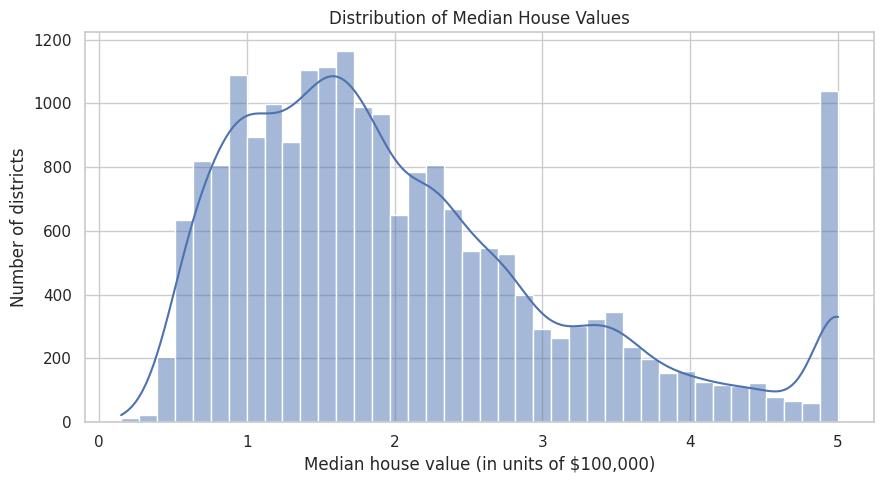

Target variable summary:


,median_house_value
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


In [5]:
# STEP 4: EXPLORE THE TARGET VARIABLE
# Understand the distribution of median house values before training models.

plt.figure(figsize=(9, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (in units of $100,000)")
plt.ylabel("Number of districts")
plt.tight_layout()
plt.show()

print("Target variable summary:")
display(df["median_house_value"].describe())

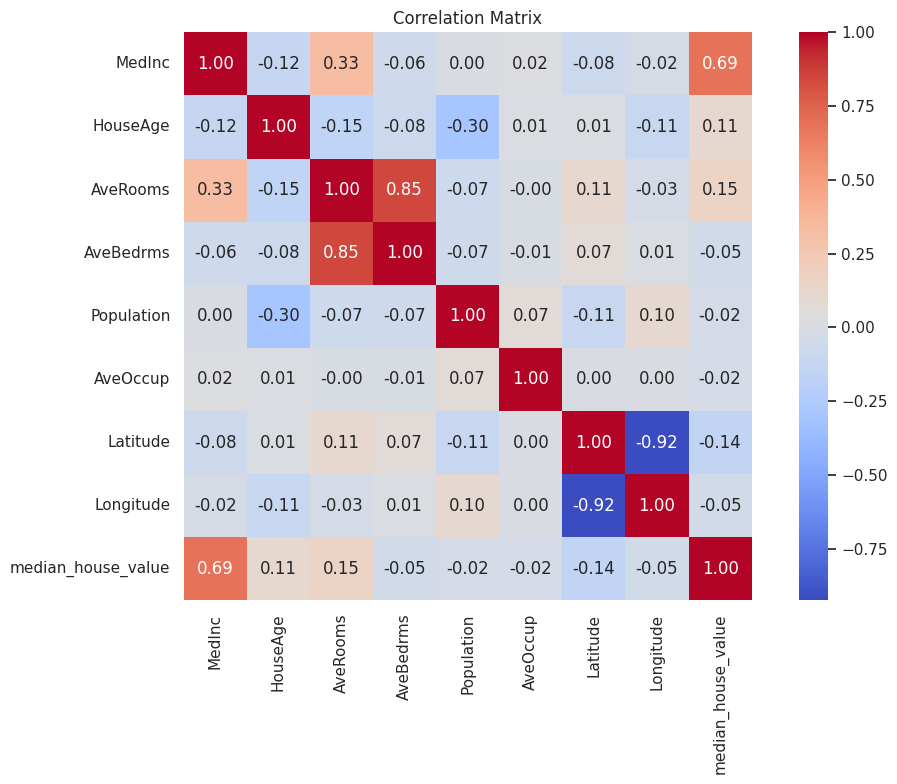

Correlation of each original feature with the target:


,correlation_with_target
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


In [6]:
# STEP 5: EXPLORE RELATIONSHIPS BETWEEN VARIABLES
# Correlation values help identify features associated with the target.
# Correlation does not by itself prove causation.

plt.figure(figsize=(11, 8))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

target_correlations = correlation_matrix["median_house_value"].drop(
    "median_house_value"
).sort_values(ascending=False)

print("Correlation of each original feature with the target:")
display(target_correlations.to_frame("correlation_with_target"))

In [7]:
# STEP 6: FEATURE ENGINEERING
# Create additional features that may help explain housing value.
#
# AveRooms and AveBedrms are average counts per household.
# Population and AveOccup can be combined to estimate household size.
# Small denominators are protected against division by zero.

df["rooms_per_household"] = df["AveRooms"]
df["bedrooms_per_room"] = df["AveBedrms"] / df["AveRooms"].replace(0, np.nan)
df["population_per_household"] = df["Population"] / df["AveOccup"].replace(0, np.nan)
df["income_per_room"] = df["MedInc"] / df["AveRooms"].replace(0, np.nan)

df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

print("New engineered features created.")
print("Updated dataset shape:", df.shape)
display(df[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_per_room",
    "median_house_value"
]].head())

New engineered features created.
Updated dataset shape: (20640, 13)


,rooms_per_household,bedrooms_per_room,population_per_household,income_per_room,median_house_value
0,6.984127,0.146591,126.0,1.192017,4.526
1,6.238137,0.155797,1138.0,1.330750,3.585
2,8.288136,0.129516,177.0,0.875637,3.521
3,5.817352,0.184458,219.0,0.970046,3.413
4,6.281853,0.172096,259.0,0.612272,3.422


In [8]:
# STEP 7: DEFINE INPUT FEATURES AND TARGET
# The target is median_house_value.
# All remaining columns are used as predictors.

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

print("Number of input features:", X.shape[1])
print("Number of target records:", y.shape[0])
print("Input feature names:")
print(X.columns.tolist())

Number of input features: 12
Number of target records: 20640
Input feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_room']


In [9]:
# STEP 8: SPLIT THE DATA
# Keep 20% of the records for final testing.
# The test data is not used to fit the models.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 16512
Testing records: 4128


In [10]:
# STEP 9: CREATE MODELING PIPELINES
# StandardScaler puts numeric features on comparable scales.
# Scaling is fitted only on the training data because it is inside each pipeline.
#
# Linear Regression is the baseline model.
# Ridge uses L2 regularization.
# Lasso uses L1 regularization.

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.001, max_iter=20000))
    ])
}

print("Models created:")
for model_name in models:
    print("-", model_name)

Models created:
- Linear Regression
- Ridge Regression
- Lasso Regression


In [11]:
# STEP 10: TRAIN THE MODELS AND EVALUATE ON THE TEST SET
# R-squared: closer to 1 is generally better.
# MSE and RMSE: lower values indicate smaller prediction errors.
# MAE: average absolute prediction error.

results = []
trained_models = {}

for model_name, model_pipeline in models.items():
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    r2 = r2_score(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predictions)

    results.append({
        "Model": model_name,
        "R-squared": r2,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae
    })

    trained_models[model_name] = model_pipeline

test_results = pd.DataFrame(results).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

print("Test-set model evaluation:")
display(test_results.round(4))

Test-set model evaluation:


,Model,R-squared,MSE,RMSE,MAE
0,Linear Regression,0.6306,0.4840,0.6957,0.5029
1,Ridge Regression,0.6306,0.4841,0.6957,0.5029
2,Lasso Regression,0.6293,0.4858,0.6970,0.5033


In [12]:
# STEP 11: APPLY 5-FOLD CROSS-VALIDATION
# Cross-validation repeatedly trains and validates a model on different
# portions of the training data. The test set remains untouched.
#
# Negative RMSE is used by scikit-learn because its scoring convention
# treats larger scores as better. We multiply by -1 to show positive RMSE.

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []

for model_name, model_pipeline in models.items():
    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Mean CV R-squared": scores["test_r2"].mean(),
        "Std CV R-squared": scores["test_r2"].std(),
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Std CV RMSE": scores["test_rmse"].std(),
        "Mean CV MAE": -scores["test_mae"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV RMSE", ascending=True
).reset_index(drop=True)

print("Five-fold cross-validation results:")
display(cv_results_df.round(4))

Five-fold cross-validation results:


,Model,Mean CV R-squared,Std CV R-squared,Mean CV RMSE,Std CV RMSE,Mean CV MAE
0,Lasso Regression,0.6482,0.0137,0.6855,0.0129,0.4961
1,Ridge Regression,0.6480,0.0140,0.6857,0.0129,0.4960
2,Linear Regression,0.6480,0.0140,0.6857,0.0129,0.4960


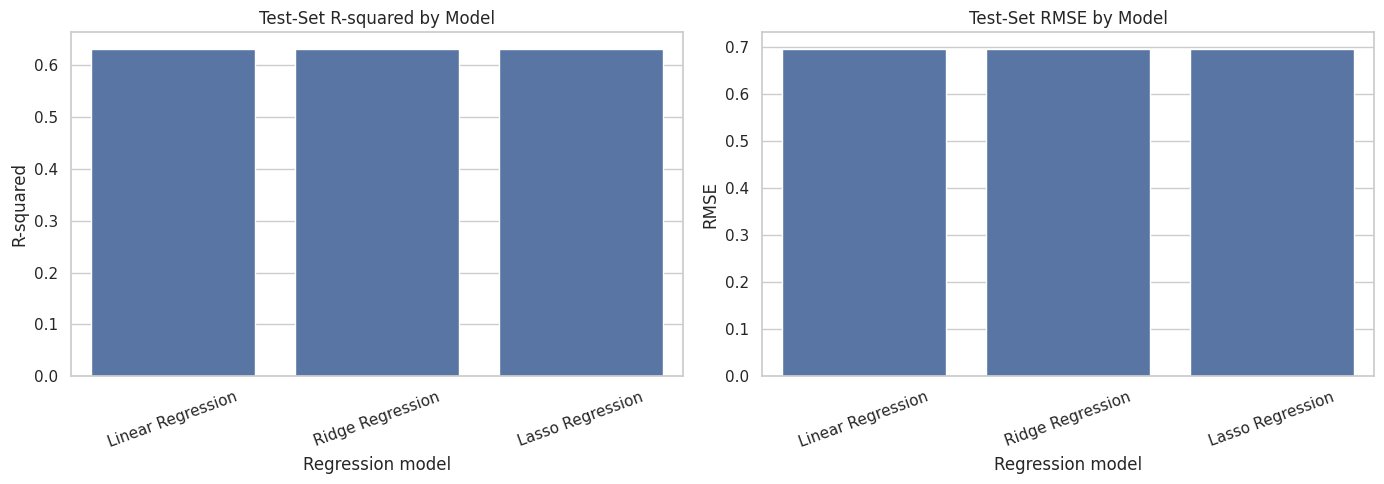

In [13]:
# STEP 12: VISUALIZE TEST-SET MODEL COMPARISON
# Compare R-squared and RMSE across the three regression models.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=test_results,
    x="Model",
    y="R-squared",
    ax=axes[0]
)
axes[0].set_title("Test-Set R-squared by Model")
axes[0].set_xlabel("Regression model")
axes[0].set_ylabel("R-squared")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=test_results,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("Test-Set RMSE by Model")
axes[1].set_xlabel("Regression model")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

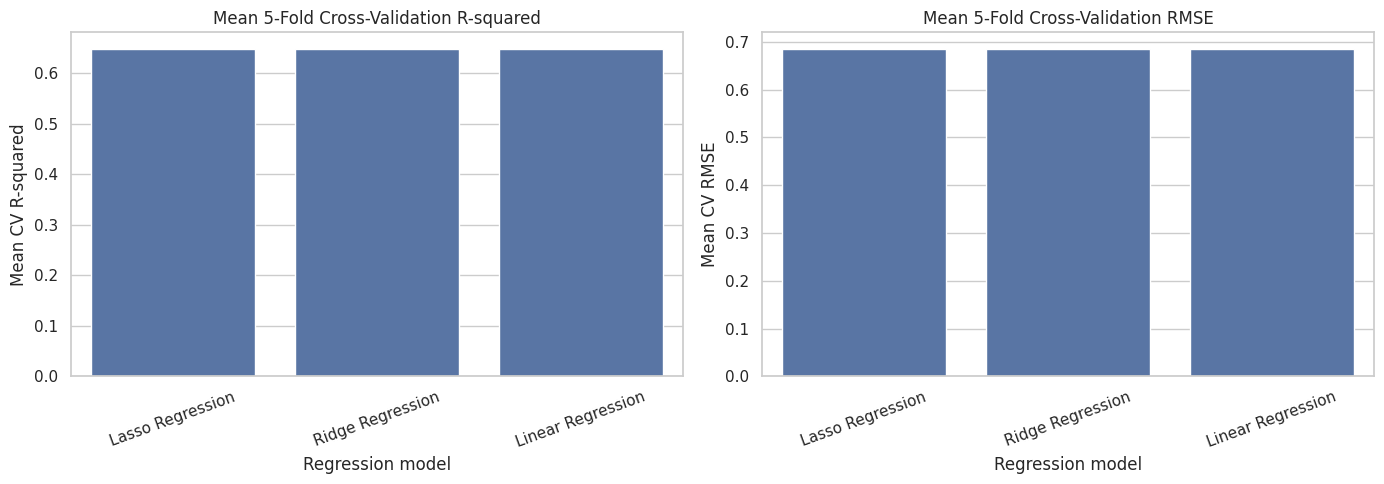

In [14]:
# STEP 13: VISUALIZE CROSS-VALIDATION RESULTS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean CV R-squared",
    ax=axes[0]
)
axes[0].set_title("Mean 5-Fold Cross-Validation R-squared")
axes[0].set_xlabel("Regression model")
axes[0].set_ylabel("Mean CV R-squared")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean CV RMSE",
    ax=axes[1]
)
axes[1].set_title("Mean 5-Fold Cross-Validation RMSE")
axes[1].set_xlabel("Regression model")
axes[1].set_ylabel("Mean CV RMSE")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

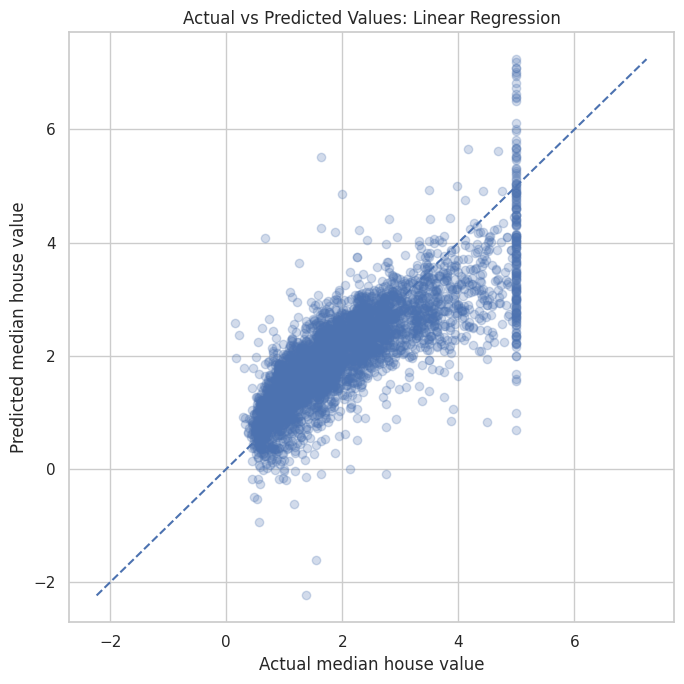

In [15]:
# STEP 14: ACTUAL VERSUS PREDICTED VALUES
# Use the model with the lowest test RMSE for this diagnostic plot.

best_model_name = test_results.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.25)
minimum_value = min(y_test.min(), best_predictions.min())
maximum_value = max(y_test.max(), best_predictions.max())
plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)
plt.title(f"Actual vs Predicted Values: {best_model_name}")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.tight_layout()
plt.show()

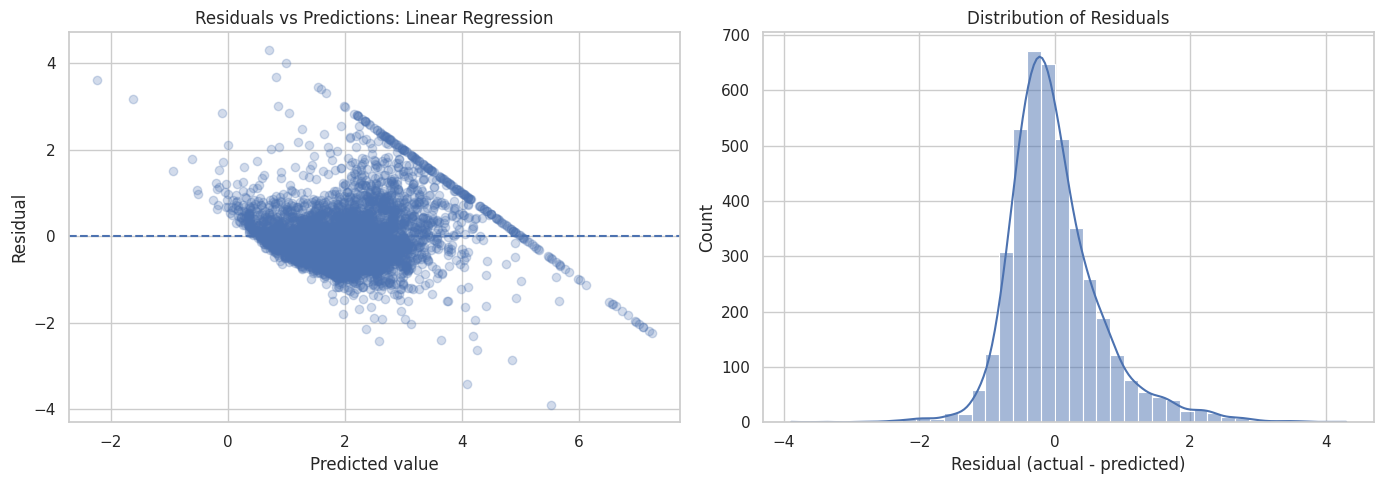

In [16]:
# STEP 15: RESIDUAL ANALYSIS
# A residual is the actual value minus the predicted value.
# Residual plots help identify systematic prediction errors.

residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(best_predictions, residuals, alpha=0.25)
axes[0].axhline(0, linestyle="--")
axes[0].set_title(f"Residuals vs Predictions: {best_model_name}")
axes[0].set_xlabel("Predicted value")
axes[0].set_ylabel("Residual")

sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

Feature coefficients for: Linear Regression


,Feature,Coefficient,Absolute Coefficient
6,Latitude,-0.8797,0.8797
7,Longitude,-0.8339,0.8339
0,MedInc,0.8223,0.8223
10,population_per_household,0.5180,0.5180
4,Population,-0.4719,0.4719
9,bedrooms_per_room,0.2088,0.2088
1,HouseAge,0.1485,0.1485
2,AveRooms,0.0702,0.0702
8,rooms_per_household,0.0702,0.0702
3,AveBedrms,-0.0453,0.0453


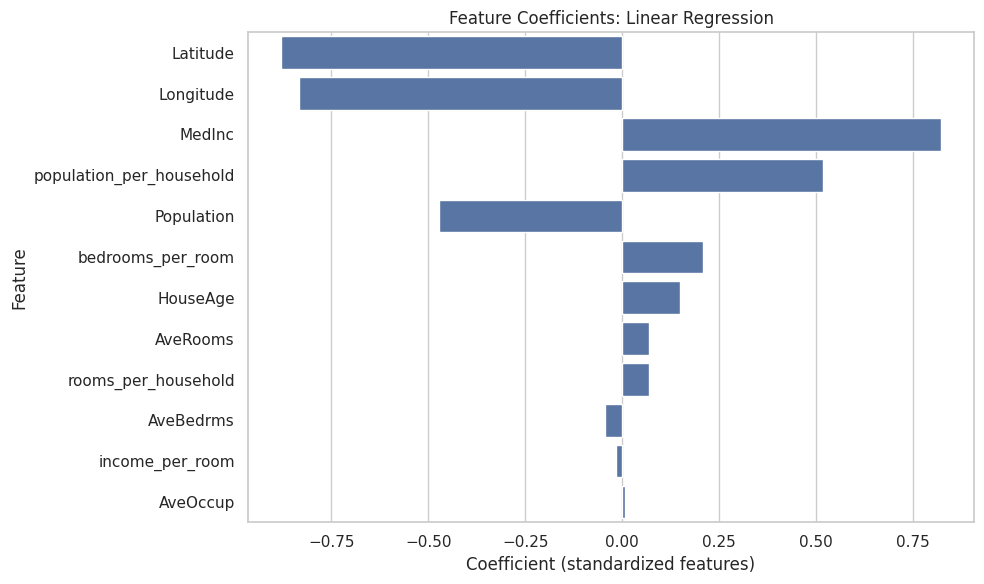

In [17]:
# STEP 16: EXAMINE MODEL COEFFICIENTS
# Coefficients are shown for the selected best model.
# Since the features are standardized, coefficient magnitudes can be
# compared more meaningfully within this fitted linear model.

fitted_regressor = best_model.named_steps["model"]

if hasattr(fitted_regressor, "coef_"):
    coefficient_table = pd.DataFrame({
        "Feature": X.columns,
        "Coefficient": fitted_regressor.coef_
    })
    coefficient_table["Absolute Coefficient"] = (
        coefficient_table["Coefficient"].abs()
    )
    coefficient_table = coefficient_table.sort_values(
        "Absolute Coefficient", ascending=False
    )

    print("Feature coefficients for:", best_model_name)
    display(coefficient_table.round(4))

    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=coefficient_table,
        x="Coefficient",
        y="Feature"
    )
    plt.title(f"Feature Coefficients: {best_model_name}")
    plt.xlabel("Coefficient (standardized features)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("The selected estimator does not expose linear coefficients.")

In [18]:
# STEP 17: IDENTIFY AND SUMMARIZE THE BEST MODEL
# The model with the lowest test RMSE is selected as the best test-set model.
# Cross-validation results are also displayed to assess generalization.

best_test_row = test_results.iloc[0]
best_cv_row = cv_results_df.iloc[0]

print("BEST MODEL BASED ON TEST RMSE")
print("--------------------------------")
print("Model:", best_test_row["Model"])
print(f"Test R-squared: {best_test_row['R-squared']:.4f}")
print(f"Test MSE:       {best_test_row['MSE']:.4f}")
print(f"Test RMSE:      {best_test_row['RMSE']:.4f}")
print(f"Test MAE:       {best_test_row['MAE']:.4f}")

print("\nBEST MODEL BASED ON MEAN CROSS-VALIDATION RMSE")
print("-----------------------------------------------")
print("Model:", best_cv_row["Model"])
print(f"Mean CV R-squared: {best_cv_row['Mean CV R-squared']:.4f}")
print(f"Mean CV RMSE:      {best_cv_row['Mean CV RMSE']:.4f}")

print("\nINTERPRETATION")
print("The test-set ranking is based on RMSE, where a lower value means")
print("smaller prediction errors. Compare it with the cross-validation")
print("ranking before deciding which model generalizes most consistently.")

BEST MODEL BASED ON TEST RMSE
--------------------------------
Model: Linear Regression
Test R-squared: 0.6306
Test MSE:       0.4840
Test RMSE:      0.6957
Test MAE:       0.5029

BEST MODEL BASED ON MEAN CROSS-VALIDATION RMSE
-----------------------------------------------
Model: Lasso Regression
Mean CV R-squared: 0.6482
Mean CV RMSE:      0.6855

INTERPRETATION
The test-set ranking is based on RMSE, where a lower value means
smaller prediction errors. Compare it with the cross-validation
ranking before deciding which model generalizes most consistently.


In [19]:
# STEP 18: SAVE MODEL EVALUATION TABLES
# These CSV files can be added to the GitHub repository if desired.

test_results.to_csv("regression_test_results.csv", index=False)
cv_results_df.to_csv("regression_cross_validation_results.csv", index=False)

print("Saved:")
print("- regression_test_results.csv")
print("- regression_cross_validation_results.csv")

Saved:
- regression_test_results.csv
- regression_cross_validation_results.csv
